# Part 5: Estimating `beta_elevation` for the bike utility in MATSim

**Goal:** estimate the coefficient of the candidate bike-utility term in the Neuchâtel MATSim scenario (eqasim `ch_cmdp`, Discrete Mode Choice):

```
U_bike += bike.betaElevation_u * delta_elevation / elevationScale_m
```

where `delta_elevation = z(destination) - z(origin)` (positive = uphill). The estimation uses the Swiss traffic microcensus (MZMV 2015) data for Neuchâtel that is already in the repository (start/end elevations were fetched from swisstopo in `add_height.ipynb`).

## Methodology

**Design:** weighted binary logit (bike vs. rest) on the microcensus data, with `delta_h` entering only the bike branch, WP expansion weights, non-parametric distance bins (bike competes with walking for short trips and with car for long ones — the distance response is therefore non-monotone and cannot be captured by a single parametric term), and person/trip-purpose controls. Uncertainty: cluster bootstrap at the person level (`HHNR`, ~4.1 trips/person).

**Two functional forms are estimated and compared** (your choice):
- **Signed**: `beta * delta_h` — the formula above.
- **Asymmetric**: `beta_gain * max(delta_h,0) + beta_loss * min(delta_h,0)` — the literature suggests uphill and downhill have different effects.

**Model linkage (important context):** MATSim's DMC selects modes with multinomial logit, and the scenario uses **gradient-based bike routing** (`EqasimTrafficModule` binds `BikeGradientBasedLinkSpeedCalculator`; speed = `5.90 - 0.3191*g - 0.010237*g^2` m/s): bike travel times are already longer on hills, so part of the elevation response already exists in the model through the travel-time term. Spec C (Section 5) computes this routing-implied response analytically from the model's own parameters.

**Scale warning (shown empirically in Section 10):** coefficients from a binary bike-vs-rest logit live on a *flatter and distorted* scale than the model's full MNL utilities (the rest alternatives have no modelled level-of-service variables here), so they cannot be transferred directly as MATSim values. The model-scale conclusion therefore combines the *structure* from the data (sign, asymmetry, significance) with the model-consistent magnitude from Spec C.

Data: `microcensus_ne_weekday_trips.csv` (6441 trips, 127 bike trips; 120 after filters). *The naive regression in `final_project_analysis.ipynb` (bike share vs. height difference) is not a utility coefficient and is ignored.*


## 1. Setup

We load the simulation's calibrated parameters with PyYAML so the analysis uses *exactly* the same values as the Neuchâtel scenario (`neuchatel_config.xml` -> `modeParametersPath` -> `calibrated_dmc_parameters.yml`, read by eqasim via reflection on field names).

In [1]:
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

TRIPS_PATH = "./microcensus_filter/microcensus_ne_weekday_trips.csv"
PERSONS_PATH = "./microcensus_filter/microcensus_ne_weekday_persons.csv"
PARAMS_PATH = "./Neuchatel_10pct/calibrated_dmc_parameters.yml"
OUTPUT_SNIPPET_PATH = "./elevation_beta_output.yml"

# Scale of the elevation term: U += beta_elevation * delta_h / elevationScale_m
ELEVATION_SCALE_M = 100.0

# Maximum air-line distance for bike to be a plausible alternative (sensitivity: 10/20 km)
DIST_CAP_KM = 15.0

# Number of bootstrap replicas (clustered at person level, HHNR)
N_BOOTSTRAP = 1000

# The simulation's calibrated parameters (flat keys, the way eqasim reads them)
with open(PARAMS_PATH) as f:
    PARAMS = yaml.safe_load(f)

BETA_TT = PARAMS["bike.betaTravelTime_u_min"]
TT_EXPONENT = PARAMS["bike.travelTimeExponent"]
TIME_SCALE_MIN = PARAMS["timeScale_min"]
AGE_SCALE_YEAR = PARAMS["ageScale_year"]
BETA_AGE = PARAMS["bike.betaAge_u"]
BETA_SEX = PARAMS["bike.betaSex_u"]

# Detour factor: median (routed distance / air-line distance) of bike trips in the
# Neuchatel_10pct simulation (simulation_output/output_trips.csv.gz, main_mode == bike)
DETOUR_FACTOR = 1.477

# Reference speed on flat terrain (speed model at g = 0)
FLAT_SPEED_MS = 5.90

print("Parameters from", PARAMS_PATH)
print(f"  bike.betaTravelTime_u_min = {BETA_TT}, bike.travelTimeExponent = {TT_EXPONENT}, timeScale_min = {TIME_SCALE_MIN}")
print(f"  bike.betaAge_u = {BETA_AGE}, bike.betaSex_u = {BETA_SEX}")


Parameters from ./Neuchatel_10pct/calibrated_dmc_parameters.yml
  bike.betaTravelTime_u_min = -3.327, bike.travelTimeExponent = 0.4965, timeScale_min = 10.0
  bike.betaAge_u = 0.2192, bike.betaSex_u = -0.4513


## 2. Loading and merging

Trips are merged with persons on `HHNR` (the unique person key in the persons file). We need `alter` (age), `gesl` (sex, 1 = male) and `f40900` (bike availability).

In [2]:
trips = pd.read_csv(TRIPS_PATH, low_memory=False)
persons = pd.read_csv(PERSONS_PATH, low_memory=False, usecols=["HHNR", "alter", "gesl", "f40900"])

df = trips.merge(persons, on="HHNR", how="left", validate="many_to_one")
print(f"Trips: {len(trips)}, persons: {len(persons)}, merged: {len(df)}")


Trips: 6441, persons: 1679, merged: 6441


## 3. Variables and sample

- `y_bike`: chose bike (`wmittel = 14`).
- `delta_h = Z_Z_CH1903 - S_Z_CH1903` (metres, positive = uphill). We also build `gain = max(delta_h,0)` and `loss = min(delta_h,0)` for the asymmetric form, and `abs_h = |delta_h|` (terrain ruggedness) for the descriptives.
- `dist_km`: air-line distance in km; `-99` (missing) is replaced by the route distance `w_rdist` if available.
- Controls (estimated): trip purpose (work/education/shopping/leisure/home; baseline = other, same mapping as in `part3.3_activityspace.ipynb`), origin in home municipality (`S_BFS == W_BFS`), non-rural destination (DEGURBA = 2), retired proxy (age >= 65), age (scaled as in the model), male, distance bins [<1, 1-2, 2-5, 5-10, >=10 km].
- Predicted bike travel times (flat and gradient-adjusted) in the model's functional form — used in Spec C and the scale analysis.

Filters: known mode, distance <= 15 km, known elevations/purpose/person attributes, positive weight.

In [3]:
num = lambda s: pd.to_numeric(s, errors="coerce")

df["wmittel_num"] = num(df["wmittel"])
df["y_bike"] = (df["wmittel_num"] == 14).astype(float)

# Air-line distance in km; -99 = missing -> try route distance (w_rdist), otherwise NaN
luftlin = num(df["w_luftlin"]).where(lambda s: s > 0)
rute = num(df["w_rdist"]).where(lambda s: s > 0)
df["dist_km"] = luftlin.fillna(rute)

# Elevation difference destination - origin (metres; positive = uphill)
df["delta_h"] = num(df["Z_Z_CH1903"]) - num(df["S_Z_CH1903"])

# Purpose mapping (same mapping as in part3.3_activityspace.ipynb)
df["purpose"] = num(df["wzweck1"]).map({
    2: "work", 6: "work", 7: "work",
    3: "education", 4: "shopping", 8: "leisure",
    5: "other", 9: "other", 10: "other", 12: "other", 11: "home",
})

mask = (
    df["wmittel_num"].between(1, 17)
    & df["dist_km"].le(DIST_CAP_KM) & df["dist_km"].gt(0)
    & df["delta_h"].notna()
    & df["purpose"].notna()
    & df["alter"].notna() & df["gesl"].notna()
    & df["WP"].gt(0)
)
sample = df[mask].copy()
print(f"Sample after filters: {len(sample)} trips ({int(sample['y_bike'].sum())} bike), "
      f"{sample['HHNR'].nunique()} persons")

# --- Elevation variables ---
sample["gain_h"] = np.maximum(sample["delta_h"], 0.0) / ELEVATION_SCALE_M
sample["loss_h"] = np.minimum(sample["delta_h"], 0.0) / ELEVATION_SCALE_M   # negative
sample["abs_h"] = np.abs(sample["delta_h"])

# --- Control dummies ---
for cat in ["work", "education", "shopping", "leisure", "home"]:
    sample[f"purpose_{cat}"] = (sample["purpose"] == cat).astype(float)
sample["origin_home"] = (num(sample["S_BFS"]) == num(sample["W_BFS"])).astype(float)
sample["dest_nonrural"] = (num(sample["Z_DEGURBA"]) == 2).astype(float)
sample["retired"] = (sample["alter"] >= 65).astype(float)
sample["male"] = (num(sample["gesl"]) == 1).astype(float)
sample["age_scaled"] = np.maximum(0.0, sample["alter"] - 17) / AGE_SCALE_YEAR
sample["bike_available"] = (num(sample["f40900"]) == 1).astype(float)
for lo, hi, name in [(1, 2, "d_1_2"), (2, 5, "d_2_5"), (5, 10, "d_5_10"), (10, 99, "d_10p")]:
    sample[name] = ((sample["dist_km"] >= lo) & (sample["dist_km"] < hi)).astype(float)

# --- Predicted bike travel times in the model's functional form (for Spec C and the scale analysis) ---
d_air_m = sample["dist_km"].to_numpy() * 1000.0
g_pct = 100.0 * sample["delta_h"].to_numpy() / np.maximum(d_air_m, 1.0)
v_ms = np.clip(5.90 - 0.3191 * g_pct - 0.010237 * g_pct ** 2, 2.5, 7.5)
t_grad = DETOUR_FACTOR * d_air_m / v_ms / 60.0
t_flat = DETOUR_FACTOR * d_air_m / FLAT_SPEED_MS / 60.0
sample["tt_term_grad"] = BETA_TT * (t_grad / TIME_SCALE_MIN) ** TT_EXPONENT
sample["tt_term_flat"] = BETA_TT * (t_flat / TIME_SCALE_MIN) ** TT_EXPONENT


Sample after filters: 6115 trips (120 bike), 1475 persons


## 4. Descriptives

Note two things from the start:
- **The correlation between |delta_h| and distance is high (0.53)** — longer trips have larger elevation differences in both directions (the signed correlation is only ~0.02). Distance must therefore be controlled flexibly (bins), not parametrically.
- The weighted bike share per *signed* elevation bin is almost flat (~1.8-2.2%), but per **|delta_h| bin** it falls monotonically with ruggedness. This points to a terrain effect, not a net-difference effect.

In [4]:
print("Weighted mode shares in the sample:")
wp_by_mode = sample.groupby("wmittel_num")["WP"].sum()
for m, w_m in wp_by_mode.sort_values(ascending=False).head(8).items():
    print(f"  wmittel {int(m):>2}: {100 * w_m / sample['WP'].sum():5.2f}%")

bins_dh = [-np.inf, -50, -10, 10, 50, np.inf]
labels_dh = ["< -50 m", "-50..-10 m", "-10..10 m", "10..50 m", "> 50 m"]
bins_abs = [-1, 10, 50, 100, np.inf]
labels_abs = ["0..10 m", "10..50 m", "50..100 m", "> 100 m"]

def share_table(d, bins, labels, col):
    b = pd.cut(d[col], bins=bins, labels=labels)
    rows = []
    for lab in labels:
        g = d[b == lab]
        share = 100 * g.loc[g["y_bike"] == 1, "WP"].sum() / g["WP"].sum() if len(g) else np.nan
        rows.append({"bin": lab, "n_trips": len(g), "n_bike": int(g["y_bike"].sum()),
                     "bike_share_weighted_%": share})
    return pd.DataFrame(rows)

tab_signed = share_table(sample, bins_dh, labels_dh, "delta_h")
tab_abs = share_table(sample, bins_abs, labels_abs, "abs_h")
print("\nPer SIGNED elevation difference:"); print(tab_signed.round(2).to_string(index=False))
print("\nPer |elevation difference| (ruggedness):"); print(tab_abs.round(2).to_string(index=False))

print(f"\nCorrelation signed delta_h vs distance: {np.corrcoef(sample['delta_h'], sample['dist_km'])[0,1]:.3f}")
print(f"Correlation |delta_h| vs distance:       {np.corrcoef(sample['abs_h'], sample['dist_km'])[0,1]:.3f}")


Weighted mode shares in the sample:
  wmittel  9: 51.24%
  wmittel 15: 33.99%
  wmittel  6:  7.90%
  wmittel 14:  1.96%
  wmittel  2:  1.45%
  wmittel  5:  1.14%
  wmittel 12:  1.13%
  wmittel 16:  0.54%

Per SIGNED elevation difference:
       bin  n_trips  n_bike  bike_share_weighted_%
   < -50 m      846      14                   1.76
-50..-10 m     1145      22                   2.04
 -10..10 m     2124      50                   2.16
  10..50 m     1142      20                   1.71
    > 50 m      858      14                   1.89

Per |elevation difference| (ruggedness):
      bin  n_trips  n_bike  bike_share_weighted_%
  0..10 m     2132      50                   2.15
 10..50 m     2281      42                   1.88
50..100 m      916      22                   3.00
  > 100 m      786       6                   0.60

Correlation signed delta_h vs distance: 0.023
Correlation |delta_h| vs distance:       0.528


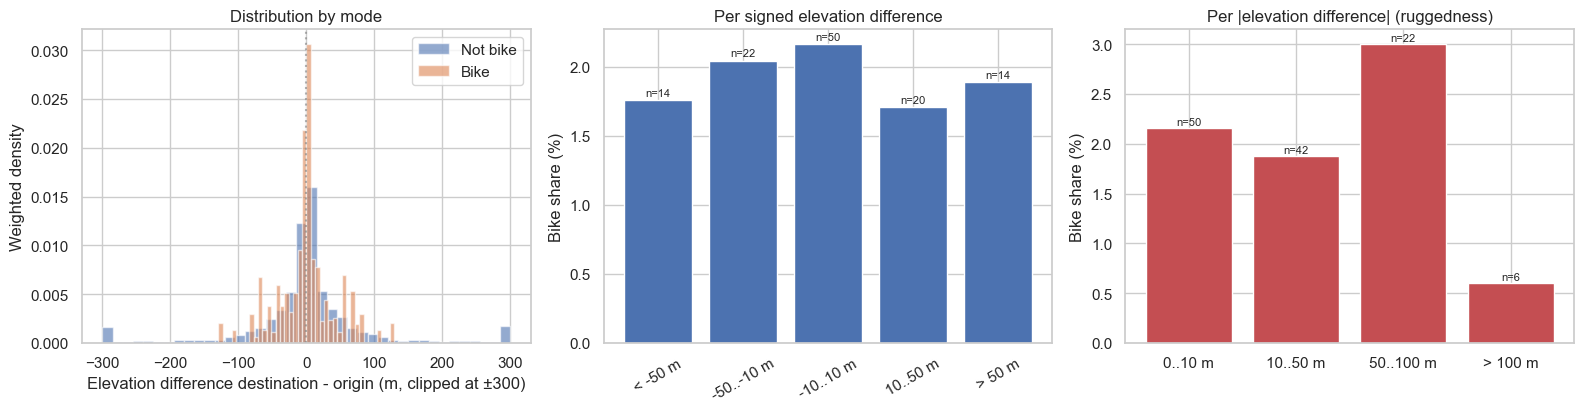

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))

clip = 300
axes[0].hist(sample.loc[sample["y_bike"] == 0, "delta_h"].clip(-clip, clip), bins=40,
             weights=sample.loc[sample["y_bike"] == 0, "WP"], alpha=0.6, density=True, label="Not bike")
axes[0].hist(sample.loc[sample["y_bike"] == 1, "delta_h"].clip(-clip, clip), bins=40,
             weights=sample.loc[sample["y_bike"] == 1, "WP"], alpha=0.6, density=True, label="Bike")
axes[0].axvline(0, color="gray", linestyle=":", alpha=0.6)
axes[0].set_xlabel("Elevation difference destination - origin (m, clipped at ±300)")
axes[0].set_ylabel("Weighted density")
axes[0].set_title("Distribution by mode")
axes[0].legend()

axes[1].bar(tab_signed["bin"], tab_signed["bike_share_weighted_%"], color="#4c72b0")
axes[1].set_ylabel("Bike share (%)"); axes[1].set_title("Per signed elevation difference")
axes[1].tick_params(axis="x", rotation=30)
for i, (share, n_b) in enumerate(zip(tab_signed["bike_share_weighted_%"], tab_signed["n_bike"])):
    axes[1].text(i, share + 0.03, f"n={n_b}", ha="center", fontsize=8)

axes[2].bar(tab_abs["bin"], tab_abs["bike_share_weighted_%"], color="#c44e52")
axes[2].set_ylabel("Bike share (%)"); axes[2].set_title("Per |elevation difference| (ruggedness)")
for i, (share, n_b) in enumerate(zip(tab_abs["bike_share_weighted_%"], tab_abs["n_bike"])):
    axes[2].text(i, share + 0.03, f"n={n_b}", ha="center", fontsize=8)

plt.tight_layout()
plt.show()


## 5. Spec C: the routing-implied elevation response (model scale)

The scenario uses gradient-based bike routing (`EqasimTrafficModule` -> `BikeGradientBasedLinkSpeedCalculator`), i.e. hills give longer travel times, and the travel-time term `betaTravelTime_u_min * (t/10)^travelTimeExponent` penalises them. With the model's own parameters we can derive how much elevation already costs in utility:

$$\frac{\partial U}{\partial h} = \beta_{TT} \cdot e \cdot (t/10)^{e-1} \cdot \frac{1}{10} \cdot \frac{dt}{dh}$$

where `dt/dh` comes from the speed model or the Parkin rule ("1 m vertical equals 8 m horizontal", from the comments in `SwissBikePredictor.java`). This is the only model-scale-consistent quantity — the data coefficients (Section 10) cannot be transferred directly.

In [6]:
def gradient_speed_ms(g_pct):
    return np.clip(5.90 - 0.3191 * g_pct - 0.010237 * g_pct ** 2, 2.5, 7.5)

def dt_dh_gradient(s_pct=0.0):
    """Seconds per vertical metre from the speed model (detour factor included)."""
    v = gradient_speed_ms(s_pct)
    return DETOUR_FACTOR * 100.0 * (0.3191 + 2 * 0.010237 * s_pct) / v ** 2

def dt_dh_parkin(v_ms=FLAT_SPEED_MS):
    """Parkin rule: 1 m vertical equals 8 m of horizontal cycling."""
    return 8.0 / v_ms

def dU_dt_min(t_min):
    """Marginal utility per additional minute of bike travel time (model parameters)."""
    return BETA_TT * TT_EXPONENT * (t_min / TIME_SCALE_MIN) ** (TT_EXPONENT - 1) / TIME_SCALE_MIN

rows = []
for t_min in [5.0, 10.0, 20.0]:
    for name, s_per_m in [("Speed model (g=0)", dt_dh_gradient(0.0)), ("Parkin (8 m rule)", dt_dh_parkin())]:
        rows.append({"travel_time_min": t_min, "dt_dh_source": name, "sec_per_m": s_per_m,
                     "beta_u_per_100m": dU_dt_min(t_min) * s_per_m / 60.0 * 100.0})

spec_c = pd.DataFrame(rows)
print(spec_c.round(4).to_string(index=False))
BETA_C_LO = spec_c["beta_u_per_100m"].min()
BETA_C_HI = spec_c["beta_u_per_100m"].max()
print(f"\nSpec C (routing-implied total response, model scale): [{BETA_C_LO:.2f}, {BETA_C_HI:.2f}] per 100 m")
print("Note: this response is ALREADY active in the scenario through the travel-time term.")


 travel_time_min      dt_dh_source  sec_per_m  beta_u_per_100m
             5.0 Speed model (g=0)     1.3540          -0.5284
             5.0 Parkin (8 m rule)     1.3559          -0.5292
            10.0 Speed model (g=0)     1.3540          -0.3728
            10.0 Parkin (8 m rule)     1.3559          -0.3733
            20.0 Speed model (g=0)     1.3540          -0.2629
            20.0 Parkin (8 m rule)     1.3559          -0.2633

Spec C (routing-implied total response, model scale): [-0.53, -0.26] per 100 m
Note: this response is ALREADY active in the scenario through the travel-time term.


## 6. Weighted logit estimator (hand-rolled Newton-Raphson)

sklearn `LogisticRegression` gives no standard errors, so we implement weighted MLE ourselves (Newton-Raphson). Since the main model is fully estimated (no offset), sklearn and NR **must** give identical point estimates — this is used as the verification in Section 7.

In [7]:
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -500, 500)))

def fit_weighted_logit(X, y, w, max_iter=200, tol=1e-11):
    """Weighted binary logit via Newton-Raphson. Returns beta, logL, information matrix."""
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)
    w = np.asarray(w, dtype=float)

    beta = np.zeros(X.shape[1])
    for _ in range(max_iter):
        p = sigmoid(X @ beta)
        Wd = w * p * (1 - p)
        H = X.T @ (X * Wd[:, None])
        grad = X.T @ (w * (y - p))
        step = np.linalg.solve(H + 1e-10 * np.eye(X.shape[1]), grad)
        beta = beta + step
        if np.max(np.abs(step)) < tol:
            break

    eta = X @ beta
    p = sigmoid(eta)
    ll = float(np.sum(w * (y * eta - np.logaddexp(0.0, np.clip(eta, -500, 500)))))
    H = X.T @ (X * (w * p * (1 - p))[:, None])
    return beta, ll, H

def coefficient_table(beta, H, names):
    se = np.sqrt(np.clip(np.diag(np.linalg.pinv(H)), 0, None))
    z = beta / se
    pv = 2 * stats.norm.sf(np.abs(z))
    tab = pd.DataFrame({"coefficient": names, "estimate": beta.round(4), "SE_naive": se.round(4),
                        "z": z.round(2), "p_value": pv.round(4)})
    return tab

def lr_test(ll_full, ll_reduced, df=1):
    lr = 2.0 * (ll_full - ll_reduced)
    return lr, stats.chi2.sf(lr, df)


## 7. Main model: controlled weighted binary logit

$$V_{bike} - V_{rest} = \text{ASC} + \beta \cdot \Delta h / 100 + \text{controls}$$

Controls: purpose, origin-at-home, non-rural destination, retired, age (model's scaling), male, distance bins. Everything is estimated freely; weights are normalised to sum to n (point estimates unchanged, naive SE and LR conservative). Two elevation forms are estimated:

- **Spec A (signed)**: one coefficient on `delta_h/100` — your formula.
- **Spec D (asymmetric)**: `beta_gain * max(delta_h,0)/100 + beta_loss * min(delta_h,0)/100`.

Spec A is nested in Spec D (restriction `beta_gain = beta_loss`), so they can be LR-tested directly against each other.

In [8]:
CTRL_COLS = ["purpose_work", "purpose_education", "purpose_shopping", "purpose_leisure", "purpose_home",
            "origin_home", "dest_nonrural", "retired", "age_scaled", "male",
            "d_1_2", "d_2_5", "d_5_10", "d_10p"]

y = sample["y_bike"].to_numpy()
w_raw = sample["WP"].to_numpy(dtype=float)
w = w_raw * len(w_raw) / w_raw.sum()   # normalised to sum = n

def design(d, mode="signed", extra_cols=None):
    cols = list(extra_cols) if extra_cols else []
    ctrl = d[CTRL_COLS + cols].to_numpy()
    if mode == "signed":
        elev = (d["delta_h"].to_numpy() / ELEVATION_SCALE_M).reshape(-1, 1)
        names_e = ["beta_elevation (per 100 m)"]
    elif mode == "asym":
        elev = np.column_stack([d["gain_h"], d["loss_h"]])
        names_e = ["beta_gain (uphill, per 100 m)", "beta_loss (downhill, per 100 m)"]
    else:
        elev = np.zeros((len(d), 0)); names_e = []
    X = np.column_stack([np.ones(len(d)), elev, ctrl])
    names = ["ASC"] + names_e + CTRL_COLS + cols
    # Drop columns without variation (e.g. distance bins outside a subsample)
    keep = np.ptp(X, axis=0) > 0
    keep[0] = True
    return X[:, keep], [n for n, k in zip(names, keep) if k]

# --- Spec A: signed ---
X_a, names_a = design(sample, "signed")
beta_a, ll_a, H_a = fit_weighted_logit(X_a, y, w)
tab_a = coefficient_table(beta_a, H_a, names_a)
print("=== SPEC A: signed elevation difference (your formula) ===")
print(tab_a.to_string(index=False))

X_a0, _ = design(sample, "none")
beta_a0, ll_a0, _ = fit_weighted_logit(X_a0, y, w)
lr_a, p_lr_a = lr_test(ll_a, ll_a0)
se_a_full = np.sqrt(np.clip(np.diag(np.linalg.pinv(H_a)), 0, None))
i_elev = names_a.index("beta_elevation (per 100 m)")
ci_a = beta_a[i_elev] + np.array([-1, 1]) * 1.96 * se_a_full[i_elev]
print(f"\nLR test beta_elevation = 0: LR = {lr_a:.3f}, p = {p_lr_a:.4f}")
print(f"95% naive CI for beta_elevation: [{ci_a[0]:.4f}, {ci_a[1]:.4f}]")


=== SPEC A: signed elevation difference (your formula) ===
               coefficient  estimate  SE_naive     z  p_value
                       ASC   -4.2955    0.5361 -8.01   0.0000
beta_elevation (per 100 m)   -0.0005    0.0962 -0.00   0.9962
              purpose_work    1.2610    0.4242  2.97   0.0030
         purpose_education   -0.2497    0.5299 -0.47   0.6375
          purpose_shopping    0.6303    0.4692  1.34   0.1792
           purpose_leisure    1.2873    0.4107  3.13   0.0017
              purpose_home    2.9455    1.0528  2.80   0.0051
               origin_home    0.4140    0.2641  1.57   0.1169
             dest_nonrural    0.0028    0.2666  0.01   0.9916
                   retired    1.0508    0.4408  2.38   0.0171
                age_scaled   -0.3530    0.0785 -4.49   0.0000
                      male    0.0835    0.1890  0.44   0.6587
                     d_1_2   -0.2496    0.2552 -0.98   0.3280
                     d_2_5   -0.6488    0.2807 -2.31   0.0208
           

In [9]:
# --- Spec D: asymmetric ---
X_d, names_d = design(sample, "asym")
beta_d, ll_d, H_d = fit_weighted_logit(X_d, y, w)
tab_d = coefficient_table(beta_d, H_d, names_d)
print("=== SPEC D: asymmetric uphill/downhill ===")
print(tab_d.head(4).to_string(index=False))

lr_ad, p_ad = lr_test(ll_d, ll_a, df=1)   # Spec A nested in Spec D
X_d0, _ = design(sample, "none")
_, ll_d0, _ = fit_weighted_logit(X_d0, y, w)
lr_d, p_lr_d = lr_test(ll_d, ll_d0, df=2)
print(f"\nLR test symmetry (gain = loss, D vs A): LR = {lr_ad:.3f}, p = {p_ad:.4f}")
print(f"LR test both = 0 (D vs no elevation):     LR = {lr_d:.3f}, p = {p_lr_d:.4f}")

# --- Verification: NR vs sklearn (identical design, fully free model) ---
from sklearn.linear_model import LogisticRegression
lr_sk = LogisticRegression(penalty=None, fit_intercept=False, solver="lbfgs",
                           max_iter=5000, tol=1e-12)
lr_sk.fit(X_d, y, sample_weight=w_raw)
dev = np.abs(beta_d - lr_sk.coef_[0]).max()
print(f"\nVERIFICATION: max deviation NR vs sklearn = {dev:.2e} (should be < 1e-4)")


=== SPEC D: asymmetric uphill/downhill ===
                    coefficient  estimate  SE_naive     z  p_value
                            ASC   -4.2607    0.5345 -7.97   0.0000
  beta_gain (uphill, per 100 m)   -0.4859    0.2591 -1.87   0.0608
beta_loss (downhill, per 100 m)    0.4887    0.2583  1.89   0.0585
                   purpose_work    1.3073    0.4245  3.08   0.0021

LR test symmetry (gain = loss, D vs A): LR = 7.924, p = 0.0049
LR test both = 0 (D vs no elevation):     LR = 7.924, p = 0.0190



VERIFICATION: max deviation NR vs sklearn = 5.11e-06 (should be < 1e-4)


## 8. Honest uncertainty: cluster bootstrap at the person level (`HHNR`)

Persons have ~4.1 trips in the sample; the naive SE understates uncertainty. 1000 person resamples with replacement give percentile CIs for both forms.

In [10]:
rng = np.random.default_rng(42)
groups = sample["HHNR"].to_numpy()
order = np.argsort(groups)
uniq, starts = np.unique(groups[order], return_index=True)
indices_by_group = np.split(order, starts[1:])

boot_vals = {"signed": [], "gain": [], "loss": []}
skipped = 0
for b in range(N_BOOTSTRAP):
    picks = rng.integers(0, len(uniq), size=len(uniq))
    sel = np.concatenate([indices_by_group[i] for i in picks])
    try:
        bb_a, _, _ = fit_weighted_logit(X_a[sel], y[sel], w[sel])
        bb_d, _, _ = fit_weighted_logit(X_d[sel], y[sel], w[sel])
        if np.max(np.abs(bb_a)) > 50 or np.max(np.abs(bb_d)) > 50:
            raise FloatingPointError("divergence (quasi-separation)")
        boot_vals["signed"].append(bb_a[1])
        boot_vals["gain"].append(bb_d[1])
        boot_vals["loss"].append(bb_d[2])
    except Exception:
        skipped += 1
boot = {k: np.array(v) for k, v in boot_vals.items()}
print(f"Bootstrap: {len(boot['signed'])} valid replicas, {skipped} skipped (divergence)")

for key, point in [("signed", beta_a[1]), ("gain", beta_d[1]), ("loss", beta_d[2])]:
    lo, hi = np.percentile(boot[key], [2.5, 97.5])
    print(f"{key:>6}: estimate {point:8.4f}   bootstrap SE {boot[key].std(ddof=1):.4f}   "
          f"95% CI [{lo:.4f}, {hi:.4f}]   P(negative) = {(boot[key] < 0).mean():.0%}")


Bootstrap: 1000 valid replicas, 0 skipped (divergence)
signed: estimate  -0.0005   bootstrap SE 0.0219   95% CI [-0.0440, 0.0433]   P(negative) = 55%
  gain: estimate  -0.4859   bootstrap SE 0.1880   95% CI [-0.9266, -0.2008]   P(negative) = 100%
  loss: estimate   0.4887   bootstrap SE 0.1891   95% CI [0.1805, 0.9306]   P(negative) = 0%


## 9. Robustness

Sensitivity of Spec D (asymmetric — the form the data supports): distance caps 10/20 km, a bike-availability control, and short trips only (< 3 km, where bike competes with walking).

In [11]:
results = []

def fit_asym_on(d, tag, extra_cols=None):
    X, names = design(d, "asym", extra_cols=extra_cols)
    ww = d["WP"].to_numpy(float); ww = ww * len(ww) / ww.sum()
    bb, _, HH = fit_weighted_logit(X, d["y_bike"].to_numpy(), ww)
    se = np.sqrt(np.clip(np.diag(np.linalg.pinv(HH)), 0, None))
    ig = names.index("beta_gain (uphill, per 100 m)")
    il = names.index("beta_loss (downhill, per 100 m)")
    results.append({"spec": tag, "beta_gain": bb[ig], "SE_gain": se[ig],
                    "beta_loss": bb[il], "SE_loss": se[il],
                    "n": len(d), "n_bike": int(d["y_bike"].sum())})

fit_asym_on(sample, "D: main (<= 15 km)")
fit_asym_on(sample[sample["dist_km"] <= 10], "D: distance cap 10 km")
fit_asym_on(sample[sample["dist_km"] <= 20], "D: distance cap 20 km")
fit_asym_on(sample[sample["dist_km"] < 3], "D: short trips only (< 3 km)")
fit_asym_on(sample, "D: + bike availability control", extra_cols=["bike_available"])

res_df = pd.DataFrame(results)
print(res_df.round(4).to_string(index=False))


                          spec  beta_gain  SE_gain  beta_loss  SE_loss    n  n_bike
            D: main (<= 15 km)    -0.4859   0.2591     0.4887   0.2583 6115     120
         D: distance cap 10 km    -0.2920   0.2703     0.2662   0.2612 5758     119
         D: distance cap 20 km    -0.4859   0.2591     0.4887   0.2583 6115     120
  D: short trips only (< 3 km)    -0.2479   0.4723    -0.1361   0.3683 4179      93
D: + bike availability control    -0.4888   0.2619     0.4919   0.2596 6115     120


## 10. Can the data coefficients be transferred directly to MATSim? (scale analysis)

A binary bike-vs-rest logit has no modelled level-of-service variables for the rest alternatives (walk/car/transit have no travel-time term here), so its scale is *not* the model's utility scale. Two empirical tests:

1. **Anchor test**: let the model's travel-time term (flat terrain, the model's functional form) enter as a free covariate. If the data and model scales matched, its coefficient (lambda) should be close to 1.
2. **Person-term comparison**: estimate age/sex/retired freely and compare signs with the model's calibrated values.

In [12]:
# 1) Anchor test: lambda on the model's travel-time term (flat terrain, free coefficient)
X_anchor, names_anchor = design(sample, "signed")
X_anchor = np.column_stack([X_anchor, sample["tt_term_flat"].to_numpy()])
names_anchor = names_anchor + ["lambda (model travel-time term)"]
beta_anc, ll_anc, H_anc = fit_weighted_logit(X_anchor, y, w)
tab_anc = coefficient_table(beta_anc, H_anc, names_anchor)
print("Anchor test (lambda should be close to 1.0 if the scales match):")
print(tab_anc.loc[tab_anc["coefficient"].isin(["beta_elevation (per 100 m)", "lambda (model travel-time term)"])].to_string(index=False))

# 2) Person terms: data vs the model's calibrated values
data_person = {
    "age_scaled": beta_a[list(names_a).index("age_scaled")],
    "male": beta_a[list(names_a).index("male")],
    "retired": beta_a[list(names_a).index("retired")],
}
model_person = {"age_scaled": BETA_AGE, "male": BETA_SEX, "retired": PARAMS["bike.betaRetired_u"]}
comp = pd.DataFrame({
    "term": list(data_person.keys()),
    "data_estimate": [data_person[k] for k in data_person],
    "model_value": [model_person[k] for k in data_person],
})
print("\nPerson terms: data vs model (same sign expected if the scale were transferable):")
print(comp.round(4).to_string(index=False))
print('''
CONCLUSION: lambda is far from 1 (and imprecise), and the person terms even
have the OPPOSITE sign of the model's. The binary-logit coefficients cannot
be transferred directly as MATSim values. The use of the data is therefore:
direction/structure/significance from the logit, magnitude from Spec C (model scale).
''')


Anchor test (lambda should be close to 1.0 if the scales match):
                    coefficient  estimate  SE_naive     z  p_value
     beta_elevation (per 100 m)   -0.0011    0.0913 -0.01   0.9905
lambda (model travel-time term)   -0.4847    0.2053 -2.36   0.0183

Person terms: data vs model (same sign expected if the scale were transferable):
      term  data_estimate  model_value
age_scaled        -0.3530       0.2192
      male         0.0835      -0.4513
   retired         1.0508      -1.0841

CONCLUSION: lambda is far from 1 (and imprecise), and the person terms even
have the OPPOSITE sign of the model's. The binary-logit coefficients cannot
be transferred directly as MATSim values. The use of the data is therefore:
direction/structure/significance from the logit, magnitude from Spec C (model scale).



## 11. Diagnostics

Calibration curve per |Δh| bin (Spec D should reproduce the observed profile), and a marginal-effect plot: P(bike) as a function of Δh for representative profiles (age 40, male, leisure purpose, origin at home, non-rural destination). The asymmetric model produces the characteristic "rugged-terrain" V-shape: both directions reduce the bike probability, uphill most (cf. the robustness table).

      bin  observed_%  predicted_%  n_bike
  0..10 m        2.15         2.50      50
 10..50 m        1.88         2.04      42
50..100 m        3.00         1.59      22
  > 100 m        0.60         0.81       6


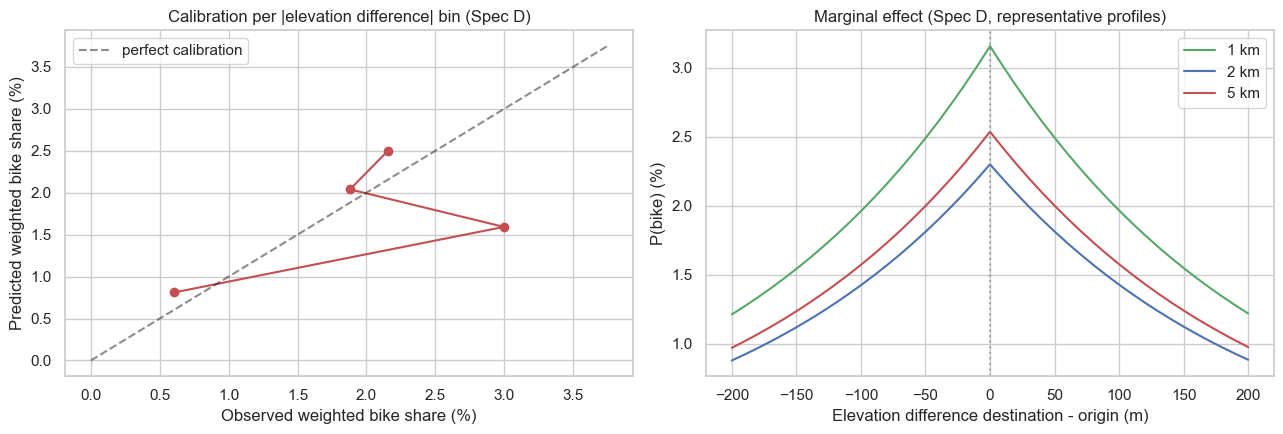

In [13]:
p_hat_d = sigmoid(X_d @ beta_d)

# Calibration per |delta_h| bin
abs_binned = pd.cut(sample["abs_h"], bins=bins_abs, labels=labels_abs)
cal_rows = []
for lab in labels_abs:
    m = (abs_binned == lab).to_numpy()
    obs = 100 * w_raw[m][y[m] == 1].sum() / w_raw[m].sum()
    pred = 100 * (w_raw[m] * p_hat_d[m]).sum() / w_raw[m].sum()
    cal_rows.append({"bin": lab, "observed_%": obs, "predicted_%": pred, "n_bike": int(y[m].sum())})
cal_tab = pd.DataFrame(cal_rows)
print(cal_tab.round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(cal_tab["observed_%"], cal_tab["predicted_%"], "o-", color="#c44e52")
lims = [0, max(cal_tab["observed_%"].max(), cal_tab["predicted_%"].max()) * 1.25]
axes[0].plot(lims, lims, "k--", alpha=0.5, label="perfect calibration")
axes[0].set_xlabel("Observed weighted bike share (%)")
axes[0].set_ylabel("Predicted weighted bike share (%)")
axes[0].set_title("Calibration per |elevation difference| bin (Spec D)")
axes[0].legend()

# Marginal effect of delta_h (Spec D) for representative profiles
pos = {n: i for i, n in enumerate(names_d)}

def profile_probability_d(dist_km, delta_h, age=40, male=True, purpose="leisure"):
    age_scaled = max(0.0, age - 17) / AGE_SCALE_YEAR
    x = np.zeros(X_d.shape[1])
    x[pos["ASC"]] = 1.0
    x[pos["beta_gain (uphill, per 100 m)"]] = max(delta_h, 0.0) / ELEVATION_SCALE_M
    x[pos["beta_loss (downhill, per 100 m)"]] = min(delta_h, 0.0) / ELEVATION_SCALE_M
    x[pos[f"purpose_{purpose}"]] = 1.0
    x[pos["origin_home"]] = 1.0
    x[pos["dest_nonrural"]] = 1.0
    x[pos["age_scaled"]] = age_scaled
    x[pos["male"]] = float(male)
    for lo, hi, name in [(1, 2, "d_1_2"), (2, 5, "d_2_5"), (5, 10, "d_5_10"), (10, 99, "d_10p")]:
        if lo <= dist_km < hi and name in pos:
            x[pos[name]] = 1.0
    return sigmoid(x @ beta_d)

dh_grid = np.arange(-200, 201, 10)
for dist_km, color in [(1.0, "#55a868"), (2.0, "#4c72b0"), (5.0, "#c44e52")]:
    axes[1].plot(dh_grid, [100 * profile_probability_d(dist_km, d) for d in dh_grid],
                 color=color, label=f"{dist_km:.0f} km")
axes[1].axvline(0, color="gray", linestyle=":", alpha=0.6)
axes[1].set_xlabel("Elevation difference destination - origin (m)")
axes[1].set_ylabel("P(bike) (%)")
axes[1].set_title("Marginal effect (Spec D, representative profiles)")
axes[1].legend()

plt.tight_layout()
plt.show()


## 12. Result and recommendation

Summary of all strands and the recommended value for `calibrated_dmc_parameters.yml` (written to `elevation_beta_output.yml`).

In [14]:
lo_s, hi_s = np.percentile(boot["signed"], [2.5, 97.5])
lo_g, hi_g = np.percentile(boot["gain"], [2.5, 97.5])

print("=" * 70)
print("SUMMARY")
print("=" * 70)
print(f'''
1) SIGNED form (your formula, beta * delta_h):
     estimate = {beta_a[1]:+.3f} per 100 m, 95% cluster CI [{lo_s:+.3f}, {hi_s:+.3f}], LR p = {p_lr_a:.3f}
     -> NOT significantly different from zero; the uphill and downhill
        effects cancel each other in the signed form.

2) ASYMMETRIC form (gain/loss):
     gain (uphill) = {beta_d[1]:+.3f} per 100 m, 95% CI [{lo_g:+.3f}, {hi_g:+.3f}]
     loss (downhill) = {beta_d[2]:+.3f} per 100 m
     -> both contribute negatively (the downhill column is negative, its
        coefficient positive): it is RUGGEDNESS (|delta_h|) that deters
        cycling, not the net difference.
        LR: asymmetric > signed, p = {p_ad:.4f}.

3) MODEL SCALE (Spec C): routing-implied elevation response already in the scenario:
     [{BETA_C_LO:.2f}, {BETA_C_HI:.2f}] per 100 m uphill via travel time.

4) SCALE TRANSFER: the binary-logit coefficients cannot be used directly as
   MATSim values (the anchor test failed; person terms have opposite signs).
''')
print("=" * 70)

# Recommendation
BETA_RECOMMENDED = 0.0        # signed form: data-consistent value
BETA_FALLBACK = -0.3          # conservative non-zero demonstration value (Spec C band)
print(f'''
RECOMMENDATION
  - Signed form (beta * delta_h): bike.betaElevation_u = {BETA_RECOMMENDED:.1f}
    Rationale: (i) the net effect is not significantly different from zero in the data,
    (ii) the scenario already penalises hills through gradient-based routing (Spec C),
    (iii) the signed form would penalise uphill trips AND reward downhill trips,
    whereas the data shows both directions are deterring (ruggedness).
  - If a non-zero value is wanted for demonstration: {BETA_FALLBACK} per 100 m
    (lower part of the Spec C band; documented as an upper bound of the residual —
    it will partially double-count with the routing response).
  - Better form per the data: an asymmetric/ruggedness term beta * |delta_h|
    (requires changing the functional form in the estimator, not just a parameter).
''')


SUMMARY

1) SIGNED form (your formula, beta * delta_h):
     estimate = -0.000 per 100 m, 95% cluster CI [-0.044, +0.043], LR p = 0.996
     -> NOT significantly different from zero; the uphill and downhill
        effects cancel each other in the signed form.

2) ASYMMETRIC form (gain/loss):
     gain (uphill) = -0.486 per 100 m, 95% CI [-0.927, -0.201]
     loss (downhill) = +0.489 per 100 m
     -> both contribute negatively (the downhill column is negative, its
        coefficient positive): it is RUGGEDNESS (|delta_h|) that deters
        cycling, not the net difference.
        LR: asymmetric > signed, p = 0.0049.

3) MODEL SCALE (Spec C): routing-implied elevation response already in the scenario:
     [-0.53, -0.26] per 100 m uphill via travel time.

4) SCALE TRANSFER: the binary-logit coefficients cannot be used directly as
   MATSim values (the anchor test failed; person terms have opposite signs).


RECOMMENDATION
  - Signed form (beta * delta_h): bike.betaElevation_u = 0.0


In [15]:
snippet = f'''# Estimated in part5_bike_elevation_beta_en.ipynb (microcensus MZMV 2015, Neuchatel)
# Signed form: the net elevation difference has no documented additional effect
# beyond gradient-based bike routing (which is already active in the scenario).
bike.betaElevation_u: {BETA_RECOMMENDED:.1f}
elevationScale_m: {ELEVATION_SCALE_M:.1f}
# Alternative (conservative non-zero demonstration value, cf. Spec C):
# bike.betaElevation_u: {BETA_FALLBACK}
'''
with open(OUTPUT_SNIPPET_PATH, "w") as f:
    f.write(snippet)
print(f"Written to {OUTPUT_SNIPPET_PATH}:")
print(snippet)


Written to ./elevation_beta_output.yml:
# Estimated in part5_bike_elevation_beta_en.ipynb (microcensus MZMV 2015, Neuchatel)
# Signed form: the net elevation difference has no documented additional effect
# beyond gradient-based bike routing (which is already active in the scenario).
bike.betaElevation_u: 0.0
elevationScale_m: 100.0
# Alternative (conservative non-zero demonstration value, cf. Spec C):
# bike.betaElevation_u: -0.3



In [16]:
print('''=== Integration into MATSim (description - NOT executed here) ===
1) SwissCmdpModeParameters.java (ch_cmdp):
     in class BikeParameters:  public double betaElevation_u = 0.0;
     at top level (next to timeScale_min):  public double elevationScale_m = 100.0;

2) SwissBikeDetailedUtilityEstimator.java:

     protected double estimateElevationUtility(DiscreteModeChoiceTrip trip) {
         double deltaElevation_m = getElevation_m(trip.getDestinationActivity())
                                 - getElevation_m(trip.getOriginActivity());
         return parameters.bike.betaElevation_u * deltaElevation_m / parameters.elevationScale_m;
     }

   getElevation_m(...) reads z from the activity's link nodes in the network
   (link.getFromNode().getCoord().getZ(); fallback: nearest network node —
   DiscreteModeChoiceTrip exposes origin/destination ACTIVITIES, not links).
   Alternative form per the data: use |deltaElevation| (ruggedness) instead of the signed value.

3) Paste the snippet above into Neuchatel_10pct/calibrated_dmc_parameters.yml
   (eqasim reads the keys via reflection on field names; 'bike.betaElevation_u'
   and 'elevationScale_m' work as flat keys).

4) Rebuild: mvn -q -pl switzerland -am package -DskipTests

Verification after integration:
 - bike.betaElevation_u = 0.0 must reproduce the current baseline exactly.
 - Compare simulated vs. observed (WP-weighted) bike share per |elevation
   difference| bin (GEH style as in part4); with a non-zero value the curve
   should flatten.
''')


=== Integration into MATSim (description - NOT executed here) ===
1) SwissCmdpModeParameters.java (ch_cmdp):
     in class BikeParameters:  public double betaElevation_u = 0.0;
     at top level (next to timeScale_min):  public double elevationScale_m = 100.0;

2) SwissBikeDetailedUtilityEstimator.java:

     protected double estimateElevationUtility(DiscreteModeChoiceTrip trip) {
         double deltaElevation_m = getElevation_m(trip.getDestinationActivity())
                                 - getElevation_m(trip.getOriginActivity());
         return parameters.bike.betaElevation_u * deltaElevation_m / parameters.elevationScale_m;
     }

   getElevation_m(...) reads z from the activity's link nodes in the network
   (link.getFromNode().getCoord().getZ(); fallback: nearest network node —
   DiscreteModeChoiceTrip exposes origin/destination ACTIVITIES, not links).
   Alternative form per the data: use |deltaElevation| (ruggedness) instead of the signed value.

3) Paste the snippet abov

## Limitations (for the report)

- **Small bike sample**: 120 bike trips after filters, 6-50 per |Δh| bin → wide bootstrap CIs. The signed coefficient being ≈ 0 is a valid finding, not a failure.
- **Scale**: a binary bike-vs-rest logit has no modelled alternative LOS (walk/car/transit); its coefficients live on a flatter/distorted scale than the model's MNL utilities (Section 10: the anchor test fails; person terms have opposite signs) → *magnitude* comes from Spec C (model scale), *structure* from the data.
- **Ruggedness-distance confounding**: |Δh| correlates 0.53 with distance; handled with non-parametric distance bins (signed Δh ⊥ distance, 0.02).
- **Routing vs. additive term**: the scenario already has gradient-based bike routing; an additive signed term would partially double-count. Spec C quantifies the overlap.
- **Two-direction effect**: the signed form rewards downhill trips; the data shows downhill also deters (the route crosses rugged terrain). An |Δh| form matches the data better.
- **Panel structure**: ~4.1 trips/person → cluster bootstrap on `HHNR`.
- **Residential self-selection** and **e-bikes** in MZMV 2015 pull the estimates toward zero.
- `retired` is an age proxy (>= 65) for the model's employment-based definition; `gesl = 1` assumed male (standard MZMV coding); elevations from the swisstopo DEM (data) vs. network node z (simulation) — use wide bins in validation.
